<a href="https://colab.research.google.com/github/sumeyyeozturk0/MLP-Digit-Recognition/blob/main/DerinOgrenme_Odev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.32MB/s]


In [2]:
train_size = 54000
val_size = 6000
train_data, val_data = random_split(train_dataset, [train_size, val_size])

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [3]:
import torch.nn as nn
import torch.nn.functional as F

class MLPModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784, 128)
        self.layer2 = nn.Linear(128, 64)
        self.layer3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.shape[0], -1)
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        x = self.layer3(x)

        return x

In [4]:
import torch.optim as optim
model = MLPModel()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [5]:
train_losses = []
val_losses = []
val_accuracies = []

epochs = 5

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    dogru_bilinen = 0
    toplam = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            val_loss = criterion(outputs, labels)

            _, predictions = torch.max(outputs, 1)
            toplam += labels.size(0)
            dogru_bilinen += (predictions == labels).sum().item()

    accuracy = 100 * dogru_bilinen / toplam

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    val_accuracies.append(accuracy)

    print(f"Epoch {epoch+1} tamamlandı! Doğrulama Başarısı: %{accuracy:.2f}")

Epoch 1 tamamlandı! Doğrulama Başarısı: %92.48
Epoch 2 tamamlandı! Doğrulama Başarısı: %94.53
Epoch 3 tamamlandı! Doğrulama Başarısı: %96.10
Epoch 4 tamamlandı! Doğrulama Başarısı: %95.33
Epoch 5 tamamlandı! Doğrulama Başarısı: %96.68


Epoch 1/5 | Train Loss: 0.0822 | Val Loss: 0.1035 | Train Acc: %97.36 | Val Acc: %96.98
Epoch 2/5 | Train Loss: 0.0731 | Val Loss: 0.1099 | Train Acc: %97.62 | Val Acc: %96.73
Epoch 3/5 | Train Loss: 0.0657 | Val Loss: 0.1110 | Train Acc: %97.86 | Val Acc: %96.93
Epoch 4/5 | Train Loss: 0.0589 | Val Loss: 0.1046 | Train Acc: %98.08 | Val Acc: %97.13
Epoch 5/5 | Train Loss: 0.0522 | Val Loss: 0.1054 | Train Acc: %98.30 | Val Acc: %97.02

Toplam Eğitim Süresi: 79 saniye
Test Başarısı (Accuracy): %96.96


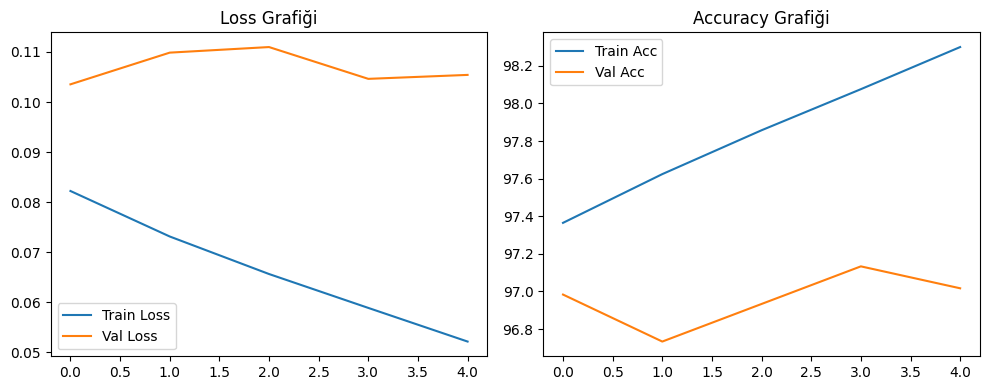

In [7]:
import time
import matplotlib.pyplot as plt
import torch

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

epochs = 5
baslangic_zamani = time.time()

for epoch in range(epochs):
    # EĞİTİM
    model.train()
    train_loss, train_dogru, train_toplam = 0, 0, 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predictions = torch.max(outputs, 1)
        train_toplam += labels.size(0)
        train_dogru += (predictions == labels).sum().item()

    ortalama_train_loss = train_loss / train_toplam
    train_accuracy = 100 * train_dogru / train_toplam

    # DOĞRULAMA
    model.eval()
    val_loss, val_dogru, val_toplam = 0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predictions = torch.max(outputs, 1)
            val_toplam += labels.size(0)
            val_dogru += (predictions == labels).sum().item()

    ortalama_val_loss = val_loss / val_toplam
    val_accuracy = 100 * val_dogru / val_toplam

    train_losses.append(ortalama_train_loss)
    val_losses.append(ortalama_val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {ortalama_train_loss:.4f} | Val Loss: {ortalama_val_loss:.4f} | Train Acc: %{train_accuracy:.2f} | Val Acc: %{val_accuracy:.2f}")

egitim_suresi = time.time() - baslangic_zamani
print(f"\nToplam Eğitim Süresi: {egitim_suresi:.0f} saniye")

# TEST
model.eval()
test_dogru, test_toplam = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predictions = torch.max(outputs, 1)
        test_toplam += labels.size(0)
        test_dogru += (predictions == labels).sum().item()

test_accuracy = 100 * test_dogru / test_toplam
print(f"Test Başarısı (Accuracy): %{test_accuracy:.2f}")

# GRAFİKLERİ ÇİZ VE KAYDET
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss Grafiği')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Acc')
plt.plot(val_accuracies, label='Val Acc')
plt.title('Accuracy Grafiği')
plt.legend()

plt.tight_layout()
plt.savefig("grafikler.png")
plt.show()

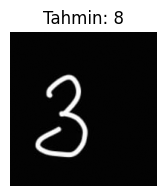

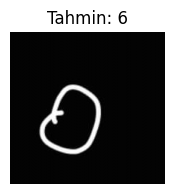

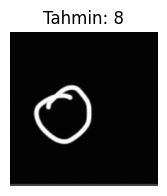

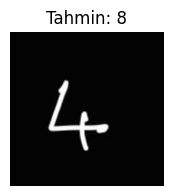

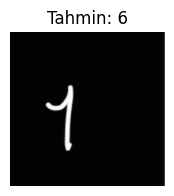

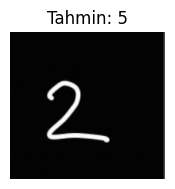

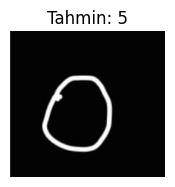

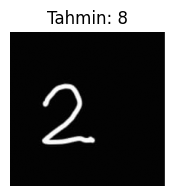

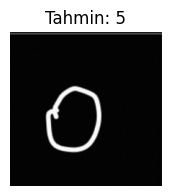

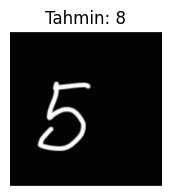

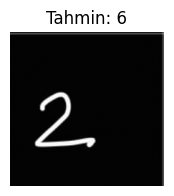

In [9]:
from PIL import Image
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt

donusum = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor()
])

toplam_resim = 11

model.eval()

with torch.no_grad():
    for i in range(1, toplam_resim + 1):
        dosya_adi = f"rakam ({i}).jpeg"

        resim = Image.open(dosya_adi).convert("L")
        resim_tensor = donusum(resim).unsqueeze(0)

        tahmin_puanlari = model(resim_tensor)
        _, nihai_karar = torch.max(tahmin_puanlari, 1)

        plt.figure(figsize=(2,2))
        plt.imshow(resim, cmap="gray")
        plt.title(f"Tahmin: {nihai_karar.item()}")
        plt.axis('off')
        plt.show()